In [36]:
import pandas as pd
import duckdb
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve


In [37]:
# # 1. Conexión a tu base de datos específica
con = duckdb.connect(r"D:\Archivos\TESIS\db\tesis.db")

# # r"D:\Archivos\proyecto aduana\Proyecto Aduana\db aduana\aduana_nueva.db"
query = """
SELECT 
    A.edad,
    A.tipo_vivienda,
    A.antiguedad_vivienda,
    A.situacion_laboral,
    A.antiguedad_laboral,
    A.ingreso_neto_mensual,
    A.total_cuotas_deudas_actuales,
    A.relacion_deuda_ingreso,
    B.score_bruto_actual,
    B.cantidad_creditos_activos,
    B.saldo_deuda,
    B.peor_atraso,
    B.cantidad_cuentas_en_mora,
    B.perfil_riesgo
FROM datos_personales A
    LEFT JOIN datos_buro B ON A.numero_ci = B.numero_ci
"""

df = con.execute(query).df()
con.close()
df

,edad,tipo_vivienda,antiguedad_vivienda,situacion_laboral,antiguedad_laboral,ingreso_neto_mensual,total_cuotas_deudas_actuales,relacion_deuda_ingreso,score_bruto_actual,cantidad_creditos_activos,saldo_deuda,peor_atraso,cantidad_cuentas_en_mora,perfil_riesgo
0,41,propia,9,empleado_informal,4,2918.15,1051.60,0.3604,604,3,82076.56,16,0,regular
1,40,propia,3,empleado_formal,7,1935.30,613.96,0.3172,576,2,46149.73,33,3,regular
2,27,propia,5,empleado_informal,3,1589.74,455.83,0.2867,580,3,45397.69,30,2,regular
3,39,propia,12,empleado_formal,14,12000.00,1490.74,0.1242,802,2,12526.45,0,0,excelente
4,30,alquilada,5,empleado_formal,1,654.45,485.17,0.7413,300,4,133169.79,127,24,muy_malo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,33,familiar,7,empleado_informal,7,2112.51,789.50,0.3737,592,5,92446.55,33,2,regular
39996,33,alquilada,4,independiente,1,517.51,388.13,0.7500,412,1,29827.61,104,5,malo
39997,36,alquilada,5,empleado_informal,4,7000.00,1215.40,0.1736,696,1,13915.00,2,1,bueno
39998,49,familiar,9,empleado_informal,25,8104.19,1840.14,0.2271,799,3,14200.58,0,0,excelente


# Tratamiento de datos
##### Definicion del target para el aprendisaje del modelo

Definición del target: 1 = Cliente Moroso (Malo), 0 = Cliente Cumplidor (Bueno)
Un cliente se considera "malo" si su peor atraso histórico superó los 90 días
o si tiene cuentas activas en mora grave.

In [38]:
df['target'] = ((df['peor_atraso'] >= 90) | (df['cantidad_cuentas_en_mora'] > 0)).astype(int)
df

,edad,tipo_vivienda,antiguedad_vivienda,situacion_laboral,antiguedad_laboral,ingreso_neto_mensual,total_cuotas_deudas_actuales,relacion_deuda_ingreso,score_bruto_actual,cantidad_creditos_activos,saldo_deuda,peor_atraso,cantidad_cuentas_en_mora,perfil_riesgo,target
0,41,propia,9,empleado_informal,4,2918.15,1051.60,0.3604,604,3,82076.56,16,0,regular,0
1,40,propia,3,empleado_formal,7,1935.30,613.96,0.3172,576,2,46149.73,33,3,regular,1
2,27,propia,5,empleado_informal,3,1589.74,455.83,0.2867,580,3,45397.69,30,2,regular,1
3,39,propia,12,empleado_formal,14,12000.00,1490.74,0.1242,802,2,12526.45,0,0,excelente,0
4,30,alquilada,5,empleado_formal,1,654.45,485.17,0.7413,300,4,133169.79,127,24,muy_malo,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,33,familiar,7,empleado_informal,7,2112.51,789.50,0.3737,592,5,92446.55,33,2,regular,1
39996,33,alquilada,4,independiente,1,517.51,388.13,0.7500,412,1,29827.61,104,5,malo,1
39997,36,alquilada,5,empleado_informal,4,7000.00,1215.40,0.1736,696,1,13915.00,2,1,bueno,1
39998,49,familiar,9,empleado_informal,25,8104.19,1840.14,0.2271,799,3,14200.58,0,0,excelente,0


##### Limpieza de valores nulos


In [39]:
# Limpieza de las filas que almenos contienen un valor nulo
df = df.dropna()
# Ver cantidad de nulos por columna
print(df.isnull().sum())

edad                            0
tipo_vivienda                   0
antiguedad_vivienda             0
situacion_laboral               0
antiguedad_laboral              0
ingreso_neto_mensual            0
total_cuotas_deudas_actuales    0
relacion_deuda_ingreso          0
score_bruto_actual              0
cantidad_creditos_activos       0
saldo_deuda                     0
peor_atraso                     0
cantidad_cuentas_en_mora        0
perfil_riesgo                   0
target                          0
dtype: int64


##### Formateo de variables para entrenamiento de los modelos

Son necesarios para que el modelo pueda entender los datos, ya que los modelos solo consumen datos numericos
Para las variables categoricas usaremos One hot encoding que es en este caso compatible con los modelos predictivo
que usaremos. Vemos los tipos de datos que contiene cada columna:



In [40]:
df.dtypes

edad                              int32
tipo_vivienda                       str
antiguedad_vivienda               int32
situacion_laboral                   str
antiguedad_laboral                int32
ingreso_neto_mensual            float64
total_cuotas_deudas_actuales    float64
relacion_deuda_ingreso          float64
score_bruto_actual                int32
cantidad_creditos_activos         int32
saldo_deuda                     float64
peor_atraso                       int32
cantidad_cuentas_en_mora          int32
perfil_riesgo                       str
target                            int64
dtype: object

**Valores categoricos ordinales:**

La regresión logística es un modelo puramente matemático y geométrico. Multiplica el valor de la variable por un peso fijo.
Para la Regresión Logística: Es recomendad One-hot Encoding, para que el modelo pueda asignar un impacto libre y realista a cada nivel de riesgo.
Sin embargo, los random forest no hacen operaciones matemáticas complejas como multiplicaciones; solo hacen preguntas de tipo "mayor que" o "menor que" para dividir los datos. por lo que tambien es recomendable usar el mismo encode. Ya que no le importan las distancias: Al Random Forest no le interesa si la distancia numérica entre 0, 1 y 2 es simétrica. Solo le importa el orden secuencial para hacer sus cortes divisorios

**Formateo de variables continuas/discretas y outliers**
Para la regresion Logistica es imprescindible, es sensible a las escalas de las variables. Por ende se hara tratamientos para los **outliers**
Para el random forest es innecesario. Los cortes de los árboles no se ven afectados por la escala.

**Random Forest**



In [41]:
# 1. Separar características (X) y objetivo (y)
X_rf = df.drop(columns=['target', 'peor_atraso', 'cantidad_cuentas_en_mora'])
y_rf = df['target']

# 2. Clasificar variables según su tipo
cat_cols = ['tipo_vivienda', 'situacion_laboral', 'perfil_riesgo']
num_cols = [
    'edad',
    'antiguedad_vivienda',
    'antiguedad_laboral',
    'ingreso_neto_mensual',
    'total_cuotas_deudas_actuales',
    'relacion_deuda_ingreso',
    'score_bruto_actual',
    'cantidad_creditos_activos',
    'saldo_deuda',
]

# 3. Pipelines de preprocesamiento
# Numéricas: solo imputación de nulos con la mediana (RF no requiere escalado)
num_transformer = Pipeline(
    steps=[('imputer', SimpleImputer(strategy='median'))]
)

# Categóricas: imputación con el valor más frecuente y One-Hot Encoding
cat_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]
)

# 4. Integrar en un ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols),
    ]
)

# 5. Crear el Pipeline completo con el modelo
rf_model = Pipeline(
    steps=[
        ('preprocesamiento', preprocessor),
        (
            'clasificador',
            RandomForestClassifier(
                n_estimators=100, random_state=42, n_jobs=-1
            ),
        ),
    ]
)


**Regresion Logistica**

In [42]:
# -------------------------------------------------------------------
# 2. Separacion de varibles dependientes e independientes
# -------------------------------------------------------------------
X_rl = df.drop(columns=['target', 'peor_atraso', 'cantidad_cuentas_en_mora'])
y_rl = df['target']

# -------------------------------------------------------------------
# 2. AGRUPAMIENTO DETALLADO DE TODAS LAS COLUMNAS DE X
# -------------------------------------------------------------------
# Float64 con distribución asimétrica
var_continuas_sesgadas = ['ingreso_neto_mensual', 'saldo_deuda']

# Float64 continuas + Int32 discretas de amplio rango
var_numericas_estandar = [
    'total_cuotas_deudas_actuales', 
    'relacion_deuda_ingreso', 
    'edad', 
    'antiguedad_laboral', 
    'antiguedad_vivienda', 
    # 'score_bruto_actual'
]

# Int32 de conteo pequeño (tratada como categórica)
var_discretas_conteos = ['cantidad_creditos_activos']

# Str categóricas de texto
var_categoricas_texto = [
    'tipo_vivienda', 
    'situacion_laboral',
    'perfil_riesgo'
]



In [43]:
# -------------------------------------------------------------------
# 3. CONSTRUCCIÓN DE SUB-PIPELINES DE TRANSFORMACIÓN
# -------------------------------------------------------------------
# A. Flotantes sesgados: Mediana -> Log -> StandardScaler
pipe_sesgadas = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

# B. Flotantes y enteros continuos/amplios: Mediana -> RobustScaler
pipe_numericas = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# C. Enteros de conteos pequeños: Moda -> OneHotEncoder
pipe_discretas_ohe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# D. Texto categórico: Moda -> OneHotEncoder
pipe_texto_ohe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

In [44]:
# -------------------------------------------------------------------
# 4. COMPOSITOR DE COLUMNAS (ColumnTransformer)
# -------------------------------------------------------------------
preprocesador = ColumnTransformer(transformers=[
    ('num_sesgadas', pipe_sesgadas, var_continuas_sesgadas),
    ('num_estandar', pipe_numericas, var_numericas_estandar),
    ('cat_discretas', pipe_discretas_ohe, var_discretas_conteos),
    ('cat_texto', pipe_texto_ohe, var_categoricas_texto)
])

In [45]:
# -------------------------------------------------------------------
# 5. PIPELINE FINAL Y MODELO LOGÍSTICO
# -------------------------------------------------------------------
modelo_logistico = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clasificador', LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000))
])

# Entrenamiento Regresion Logistica


In [46]:
# -------------------------------------------------------------------
# 6. DIVISIÓN Y ENTRENAMIENTO
# -------------------------------------------------------------------
X_train_rl, X_test_rl, y_train_rl, y_test_rl = train_test_split(X_rl, y_rl, test_size=0.2, random_state=42, stratify=y_rl)

# Entrenar todo el flujo con una sola línea
modelo_logistico.fit(X_train_rl, y_train_rl)

# Generar predicciones o probabilidades
y_pred = modelo_logistico.predict(X_test_rl)
y_proba = modelo_logistico.predict_proba(X_test_rl)[:, 1]
print(y_pred)
print(y_proba)

[0 1 1 ... 0 1 0]
[0.00155587 0.75111659 0.75908314 ... 0.49374764 0.76601909 0.00165904]


d:\Archivos\TESIS\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


# Entrenamiento Random Forest

In [ ]:
# 6. Dividir datos y entrenar
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X_rf, y_rf, test_size=0.2, random_state=42, stratify=y_rf
)

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['edad','tipo_vivienda','antiguedad_vivienda',..., 'cantidad_creditos_activos','saldo_deuda','perfil_riesgo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [49]:
# -------------------------------------------------------------------
# 4. PREDICCIONES Y EVALUACIÓN
# -------------------------------------------------------------------
y_pred_rf = rf_model.predict(X_test_rf)
y_proba_rf = rf_model.predict_proba(X_test_rf)[:, 1]

# print(y_pred_rf)
print(rf_model.predict_proba(X_test_rf))

NameError: name 'X_test_rf' is not defined

# Evaluacion de modelos

In [ ]:
def calcular_metricas_riesgo(y_true, y_proba):
    """Calcula las métricas estándar de Scoring Crediticio"""
    auc = roc_auc_score(y_true, y_proba)
    gini = 2 * auc - 1
    
    # Cálculo de Estadística KS
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    ks = np.max(tpr - fpr)
    
    return auc, gini, ks

=== COMPARATIVA DE DESEMPEÑO DE MODELOS ===
             Métrica Regresión Logística Random Forest
             ROC-AUC              0.8893        0.9135
    Coeficiente Gini              77.87%        82.70%
Estadística KS (max)              59.36%        63.25%


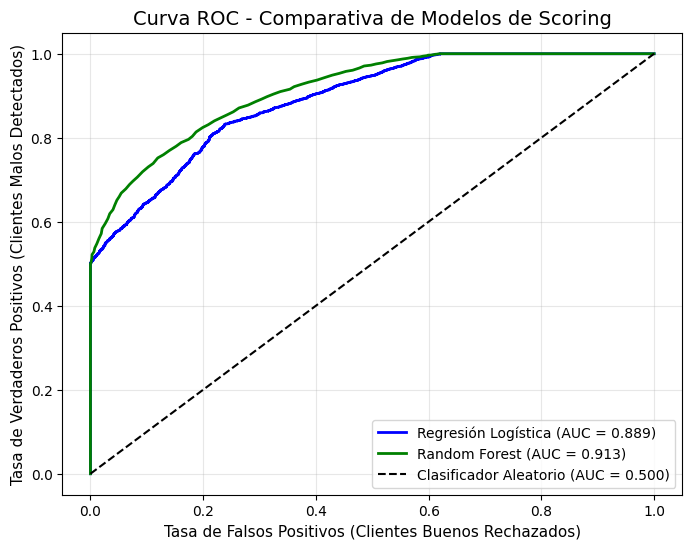

In [ ]:
# -------------------------------------------------------------------
# 1. OBTENER PROBABILIDADES DE CADA MODELO
# -------------------------------------------------------------------
# Regresión Logística
y_proba = modelo_logistico.predict_proba(X_test)[:, 1]

# Random Forest
y_proba_rf = rf_model.predict_proba(X_test_rf)[:, 1]

# -------------------------------------------------------------------
# 2. GENERAR TABLA COMPARATIVA DE MÉTRICAS
# -------------------------------------------------------------------
auc_rl, gini_rl, ks_rl = calcular_metricas_riesgo(y_test, y_proba)
auc_rf, gini_rf, ks_rf = calcular_metricas_riesgo(y_test_rf, y_proba_rf)

tabla_comparativa = pd.DataFrame({
    'Métrica': ['ROC-AUC', 'Coeficiente Gini', 'Estadística KS (max)'],
    'Regresión Logística': [f"{auc_rl:.4f}", f"{gini_rl*100:.2f}%", f"{ks_rl*100:.2f}%"],
    'Random Forest': [f"{auc_rf:.4f}", f"{gini_rf*100:.2f}%", f"{ks_rf*100:.2f}%"]
})

print("=== COMPARATIVA DE DESEMPEÑO DE MODELOS ===")
print(tabla_comparativa.to_string(index=False))

# -------------------------------------------------------------------
# 3. GRÁFICO DE CURVAS ROC
# -------------------------------------------------------------------
fpr_rl, tpr_rl, _ = roc_curve(y_test, y_proba)
fpr_rf, tpr_rf, _ = roc_curve(y_test_rf, y_proba_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rl, tpr_rl, label=f'Regresión Logística (AUC = {auc_rl:.3f})', color='blue', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='green', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.500)')

plt.title('Curva ROC - Comparativa de Modelos de Scoring', fontsize=14)
plt.xlabel('Tasa de Falsos Positivos (Clientes Buenos Rechazados)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Clientes Malos Detectados)', fontsize=11)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

Vemos que 

# Serializar el modelo

In [ ]:
# Regresion Logistica
modelo_logistico_cargado = joblib.dump(modelo_logistico, 'modelo_logistico.joblib')
#Random Forest
random_forest_cargado = joblib.dump(rf_model, 'rf_modelo.joblib')

NameError: name 'joblib' is not defined

In [ ]:
modelo_rf = pipeline_rf.named_steps['clasificador']

df_importancia = pd.DataFrame({
    'variable': nombres_vars,
    'importancia': modelo_rf.feature_importances_
}).sort_values(by='importancia', ascending=False)

print(df_importancia.head(10))